# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [ ]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [1]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play

In [2]:

# AND-OR Search Agent test 1

def and_or_value(board, current_player, root_player):
    # Kiểm tra trạng thái kết thúc
    if terminal(board):
        return utility(board, root_player)

    available = actions(board)

    # Không còn nước đi thì hòa
    if not available:
        return 0

    values = []

    for move in available:
        new_board = result(board, current_player, move)

        value = and_or_value(
            new_board,
            other(current_player),
            root_player
        )

        values.append(value)

    # OR: Chọn giá trị tốt nhất
    if current_player == root_player:
        return max(values)

    # AND: Đối thủ chọn giá trị bất lợi nhất
    return min(values)


def and_or_player(board, player=None):
    import random

    available = actions(board)

    if not available:
        raise ValueError("Bàn cờ không còn nước đi hợp lệ.")

    move_values = []

    for move in available:
        new_board = result(board, player, move)

        value = and_or_value(
            new_board,
            other(player),
            player
        )

        move_values.append((value, move))

    best_value = max(value for value, move in move_values)

    best_moves = [
        move for value, move in move_values
        if value == best_value
    ]

    return random.choice(best_moves)


## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)

    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))

            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")

            print("Please enter a valid move.")


    return(move)

# **Thực nghiệm 1: Tác tử Random**

## Start an interactive game as x

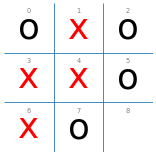

Available actions are: [8]
Your move (0-8 or -1 to end the game):
8


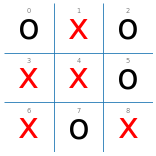

{'x': 0, 'o': 0, 'd': 1}

In [10]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

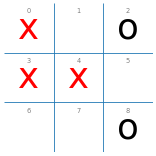

Available actions are: [1, 5, 6, 7]
Your move (0-8 or -1 to end the game):
5


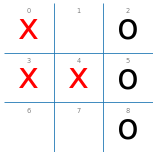

{'x': 0, 'o': 1, 'd': 0}

In [6]:
play(random_player, interactive_player, N = 1, show_final_board = True)

# **Thực nghiệm 2: Tác tử AND-OR**

## Start an interactive game as x

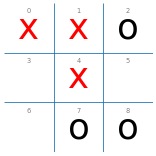

Available actions are: [3, 5, 6]
Your move (0-8 or -1 to end the game):
6


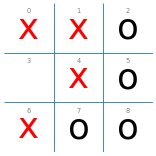

{'x': 0, 'o': 1, 'd': 0}

In [7]:
play(interactive_player, and_or_player, N=1, show_final_board=True)

## Start an interactive game as o

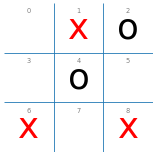

Available actions are: [0, 3, 5, 7]
Your move (0-8 or -1 to end the game):
3


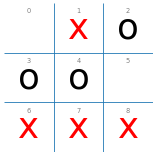

{'x': 1, 'o': 0, 'd': 0}

In [4]:
play(and_or_player, interactive_player, N=1, show_final_board=True)